# Лабораторная работа 2. Общее исследование датасета и однофакторный анализ

**Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ**
Дисциплина «Разведочный анализ и алгоритмы классификации»

**Этап CRISP-DM:** Business understanding → Data understanding.

**Цель работы:** познакомиться с датасетом Online Shoppers Purchasing Intention, проверить качество данных и описать распределение каждого признака по отдельности — сначала безотносительно целевой переменной, затем в разрезе двух классов.

**Задачи:**
1. Сформулировать бизнес-задачу и задачу анализа данных.
2. Проверить структуру данных: размер, типы, пропуски, дубликаты, логические ограничения.
3. Описать целевую переменную.
4. Однофакторный анализ числовых и категориальных признаков.
5. Однофакторный анализ в разрезе целевой переменной.
6. Собрать список особенностей данных, которые нужно учесть при подготовке признаков (lab4).

> **Правило этой и следующей работы.** На этапе разведочного анализа я фиксирую только то, что видно в данных (числа, формы распределений, различия долей). Предположения о причинах и выводы о связях признаков с покупкой здесь не делаются — они появятся только после построения моделей (lab5).

## 1. Понимание бизнес-задачи

**Бизнес-контекст.** Интернет-магазин собирает статистику сессий посетителей (Google Analytics). Большая часть сессий заканчивается без покупки. Магазину полезно уже по ходу сессии оценивать, насколько вероятна покупка: например, чтобы показывать персональное предложение или подключать консультанта только там, где это имеет смысл.

| Уровень | Формулировка |
|---|---|
| Бизнес-цель | отличать сессии, которые закончатся покупкой, от сессий без покупки |
| Цель анализа данных | бинарная классификация: по признакам сессии предсказать `Revenue` (1 — покупка, 0 — нет) и оценить вероятность покупки |
| Критерий успеха | модель заметно лучше «наивного» прогноза по ROC-AUC и PR-AUC; качество и прогнозы можно объяснить словами |

**Данные.** UCI Machine Learning Repository, датасет №468 *Online Shoppers Purchasing Intention* (Sakar C. O. et al., Neural Computing and Applications, 2019). Файл взят с зеркала на GitHub (см. `scripts/download_data.py`); ниже проверяю, что он совпадает с описанием оригинала: 12 330 сессий × 18 столбцов, 1 908 сессий с покупкой.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.ticker import PercentFormatter

from src.data import (load_raw, load, DESCRIPTIONS, NUMERIC, NOMINAL, BINARY, TARGET,
                      COUNT_DURATION, GA_METRICS, MONTH_ORDER, MONTH_RU, DATA_PATH, sha256)
from src import viz
viz.setup()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

raw = load_raw()
print("Файл:", DATA_PATH.name, "| SHA-256:", sha256(DATA_PATH)[:16], "...")
print("Размер:", raw.shape)
print("Сессий с покупкой:", int(raw[TARGET].sum()))

Файл: online_shoppers_intention.csv | SHA-256: b3055ee355f59134 ...
Размер: (12330, 18)
Сессий с покупкой: 1908


Размер и число покупок совпадают с описанием оригинала на UCI — работаю с правильным файлом.

## 2. Общее исследование датасета
### 2.1. Состав признаков

In [2]:
kind = {}
for c in raw.columns:
    if c in COUNT_DURATION and not c.endswith("Duration"):
        kind[c] = "числовой, счётчик (целый)"
    elif c.endswith("Duration"):
        kind[c] = "числовой, непрерывный (секунды)"
    elif c in GA_METRICS:
        kind[c] = "числовой, непрерывный (метрика GA)"
    elif c == "SpecialDay":
        kind[c] = "числовой, 6 значений 0…1"
    elif c in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
        kind[c] = "номинальный (целый код без порядка)"
    elif c in ["Month", "VisitorType"]:
        kind[c] = "номинальный (строка)"
    else:
        kind[c] = "бинарный"
info = pd.DataFrame({
    "описание": [DESCRIPTIONS[c] for c in raw.columns],
    "тип по смыслу": [kind[c] for c in raw.columns],
    "dtype в файле": raw.dtypes.astype(str).values,
    "уникальных": raw.nunique().values,
    "пропусков": raw.isna().sum().values,
}, index=raw.columns)
info

,описание,тип по смыслу,dtype в файле,уникальных,пропусков
Administrative,Число просмотренных страниц типа «администриро...,"числовой, счётчик (целый)",int64,27,0
Administrative_Duration,Суммарное время на страницах «администрировани...,"числовой, непрерывный (секунды)",float64,3335,0
Informational,Число просмотренных информационных страниц (о ...,"числовой, счётчик (целый)",int64,17,0
Informational_Duration,"Суммарное время на информационных страницах, с","числовой, непрерывный (секунды)",float64,1258,0
ProductRelated,"Число просмотренных страниц, связанных с товарами","числовой, счётчик (целый)",int64,311,0
ProductRelated_Duration,"Суммарное время на товарных страницах, с","числовой, непрерывный (секунды)",float64,9551,0
BounceRates,Средний показатель отказов (Google Analytics) ...,"числовой, непрерывный (метрика GA)",float64,1872,0
ExitRates,Средний показатель выходов (Google Analytics) ...,"числовой, непрерывный (метрика GA)",float64,4777,0
PageValues,Средняя «ценность страницы» (Google Analytics)...,"числовой, непрерывный (метрика GA)",float64,2704,0
SpecialDay,Близость даты сессии к «особому дню» (14 февра...,"числовой, 6 значений 0…1",float64,6,0


**Что видно из таблицы.**
* В данных 17 признаков и целевая переменная `Revenue`; пропусков нет ни в одном столбце.
* Числовых признаков 10: шесть описывают поведение в сессии (сколько страниц трёх типов просмотрено и сколько секунд на них проведено), три — усреднённые метрики Google Analytics по страницам сессии (`BounceRates`, `ExitRates`, `PageValues`), и `SpecialDay` — близость к праздничной дате, который принимает всего 6 значений.
* `OperatingSystems`, `Browser`, `Region`, `TrafficType` записаны целыми числами, но это **коды**: браузер «2» не «больше» браузера «1». По смыслу это номинальные признаки, и обращаться с ними как с числами нельзя — это учитывается в lab4.
* `Month` и `VisitorType` — строковые номинальные признаки; `Weekend` и `Revenue` — логические (True/False).

In [3]:
raw.head(8)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False


### 2.2. Пропуски, дубликаты, допустимые значения

In [4]:
print("Пропусков всего:", int(raw.isna().sum().sum()))
dup_mask = raw.duplicated(keep=False)
print("Полных дубликатов строк (лишних копий):", int(raw.duplicated().sum()),
      "| строк, у которых есть копия:", int(dup_mask.sum()))
print("\nКак выглядят дублирующиеся строки:")
display(raw[dup_mask].groupby(list(raw.columns), observed=True).size()
        .sort_values(ascending=False).head(5).rename("копий").reset_index()
        [["Administrative", "Informational", "ProductRelated", "ProductRelated_Duration",
          "BounceRates", "ExitRates", "PageValues", "Month", "VisitorType", "Revenue", "копий"]])
print("Доля покупок среди дублирующихся строк:", raw.loc[dup_mask, TARGET].mean())

Пропусков всего: 0
Полных дубликатов строк (лишних копий): 125 | строк, у которых есть копия: 201

Как выглядят дублирующиеся строки:


,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Month,VisitorType,Revenue,копий
0,0,0,1,0.0,0.2,0.2,0.0,Mar,Returning_Visitor,False,14
1,0,0,1,0.0,0.2,0.2,0.0,Mar,Returning_Visitor,False,7
2,0,0,1,0.0,0.2,0.2,0.0,May,Returning_Visitor,False,7
3,0,0,1,0.0,0.2,0.2,0.0,May,Returning_Visitor,False,6
4,0,0,1,0.0,0.2,0.2,0.0,Dec,Other,False,5


Доля покупок среди дублирующихся строк: 0.0


**Наблюдения.**
* Пропусков нет.
* Полностью совпадающих строк 201, из них 125 — «лишние» копии. Все такие строки — сессии с одной товарной страницей (`ProductRelated` = 1–2), нулевым временем и максимальными значениями `BounceRates` = `ExitRates` = 0,2; ни одна из них не закончилась покупкой.
* Совпадение строк здесь не обязательно ошибка выгрузки: у таких коротких сессий почти все признаки равны нулю, и разные посетители легко дают одинаковый набор значений. Решение, что с ними делать, принимается на этапе подготовки (lab4).

In [5]:
checks = {
    "отрицательные счётчики/длительности": int((raw[COUNT_DURATION] < 0).any(axis=1).sum()),
    "BounceRates или ExitRates вне [0, 0.2]": int((~raw[["BounceRates", "ExitRates"]].apply(lambda s: s.between(0, 0.2))).any(axis=1).sum()),
    "PageValues < 0": int((raw["PageValues"] < 0).sum()),
    "SpecialDay вне {0,0.2,…,1}": int((~raw["SpecialDay"].isin([0, .2, .4, .6, .8, 1.0])).sum()),
    "страниц нет, а время > 0": int(sum(((raw[p] == 0) & (raw[p + "_Duration"] > 0)).sum()
                                        for p in ["Administrative", "Informational", "ProductRelated"])),
    "сессий без единой страницы трёх типов": int((raw[["Administrative", "Informational", "ProductRelated"]].sum(axis=1) == 0).sum()),
}
for p in ["Administrative", "Informational", "ProductRelated"]:
    checks[f"{p} > 0, а время = 0"] = int(((raw[p] > 0) & (raw[p + "_Duration"] == 0)).sum())
pd.Series(checks, name="число строк").to_frame()

,число строк
отрицательные счётчики/длительности,0
"BounceRates или ExitRates вне [0, 0.2]",0
PageValues < 0,0
"SpecialDay вне {0,0.2,…,1}",0
"страниц нет, а время > 0",0
сессий без единой страницы трёх типов,6
"Administrative > 0, а время = 0",135
"Informational > 0, а время = 0",226
"ProductRelated > 0, а время = 0",717


**Проверка допустимых значений.**
* Отрицательных счётчиков и длительностей нет; `BounceRates` и `ExitRates` лежат в [0; 0,2], `PageValues` ≥ 0, `SpecialDay` принимает только значения 0; 0,2; …; 1.
* Нет ни одной сессии, где страниц какого-то типа 0, а время на них положительно.
* Обратная ситуация встречается: страницы просмотрены, а время равно 0 (135 / 226 / 717 сессий для трёх типов страниц). Это особенность измерения в Google Analytics: время на странице считается как разница между отметками последовательных просмотров, поэтому время на последней странице сессии не фиксируется. Значит, нулевое время — не пропуск, а свойство источника данных.
* 6 сессий не содержат ни одной страницы трёх учтённых типов.

In [6]:
df = load()  # те же данные: Month/коды как category, Weekend и Revenue как 0/1
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


**Описательные статистики.**
* У всех счётчиков и длительностей среднее заметно больше медианы (например, `ProductRelated_Duration`: среднее 1 195 с, медиана 599 с, максимум 63 974 с ≈ 17,8 ч) — распределения скошены вправо.
* У `Informational`, `Informational_Duration`, `PageValues` и `SpecialDay` даже 75-й перцентиль равен 0: больше трёх четвертей сессий имеют нулевое значение.
* `Weekend` = 1 у 23,3 % сессий.

## 3. Целевая переменная `Revenue`

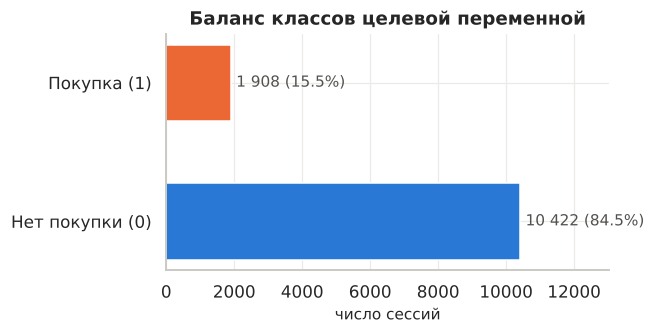

Отношение классов 0:1 = 5.46


In [7]:
vc = df[TARGET].value_counts().sort_index()
share = vc / vc.sum()
fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh(["Нет покупки (0)", "Покупка (1)"], vc.values, color=viz.CLASS_PALETTE, height=0.55)
for b, n, s in zip(bars, vc.values, share.values):
    ax.text(b.get_width() + 150, b.get_y() + b.get_height() / 2, f"{n:,} ({s:.1%})".replace(",", " "),
            va="center", fontsize=10, color="#52514e")
ax.set_xlim(0, vc.max() * 1.25); ax.set_xlabel("число сессий")
ax.set_title("Баланс классов целевой переменной")
plt.tight_layout(); plt.show()
print("Отношение классов 0:1 =", round(vc[0] / vc[1], 2))

**Целевая переменная.** Покупкой закончились 1 908 сессий из 12 330 (15,5 %), без покупки — 10 422 (84,5 %); на одну «покупку» приходится 5,46 «непокупки».

Классы несбалансированы. Это сразу влияет на выбор метрик для будущих моделей: модель, которая всегда отвечает «нет покупки», получит accuracy 84,5 %, ничего не умея. Поэтому в lab5 основными будут ROC-AUC, PR-AUC и F1/полнота по классу «покупка», а разбиение на обучающую и тестовую выборки — стратифицированным.

## 4. Однофакторный анализ числовых признаков
### 4.1. Сводка формы распределений

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

num_summary = pd.DataFrame({
    "среднее": df[NUMERIC].mean(),
    "медиана": df[NUMERIC].median(),
    "95-й перцентиль": df[NUMERIC].quantile(.95),
    "максимум": df[NUMERIC].max(),
    "доля нулей": (df[NUMERIC] == 0).mean(),
    "асимметрия": df[NUMERIC].skew(),
    "выбросов по IQR": [iqr_outliers(df[c]) for c in NUMERIC],
}).round(3)
num_summary.style.format({"доля нулей": "{:.1%}"}).background_gradient(
    subset=["асимметрия"], cmap=viz.SEQ).background_gradient(subset=["доля нулей"], cmap=viz.SEQ)

,среднее,медиана,95-й перцентиль,максимум,доля нулей,асимметрия,выбросов по IQR
Administrative,2.315000,1.000000,9.000000,27.000000,46.8%,1.960000,404
Administrative_Duration,80.819000,7.500000,348.266000,3398.750000,47.9%,5.616000,1172
Informational,0.504000,0.000000,3.000000,24.000000,78.7%,4.036000,2631
Informational_Duration,34.472000,0.000000,195.000000,2549.375000,80.5%,7.579000,2405
ProductRelated,31.731000,18.000000,109.000000,705.000000,0.3%,4.342000,987
ProductRelated_Duration,1194.746000,598.937000,4300.289000,63973.522000,6.1%,7.263000,961
BounceRates,0.022000,0.003000,0.200000,0.200000,44.8%,2.948000,1551
ExitRates,0.043000,0.025000,0.200000,0.200000,0.6%,2.149000,1099
PageValues,5.889000,0.000000,38.161000,361.764000,77.9%,6.383000,2730
SpecialDay,0.061000,0.000000,0.600000,1.000000,89.9%,3.303000,1251


**Наблюдения по числовым признакам.**
* Почти у всех признаков большая доля нулей: `SpecialDay` — 89,9 %, `Informational_Duration` — 80,5 %, `Informational` — 78,7 %, `PageValues` — 77,9 %, `Administrative(_Duration)` — около 47–48 %, `BounceRates` — 44,8 %.
* Коэффициент асимметрии везде положительный и большой (от 1,96 у `Administrative` до 7,58 у `Informational_Duration`).
* Правило 1,5·IQR помечает как «выбросы» от 404 до 2 730 значений на признак. У признаков с медианой и третьим квартилем, равными нулю (`PageValues`, `Informational`), «выбросом» по этому правилу оказывается любое ненулевое значение — поэтому IQR-правило для них не годится как критерий удаления, это просто описание формы распределения.

### 4.2. Гистограммы: исходная шкала и шкала `log1p`
Счётчики и длительности имеют длинный правый хвост, поэтому каждую величину показываю дважды: в исходных единицах и после `log1p(x) = ln(1 + x)` (нули при этом остаются нулями). Красная линия — медиана.

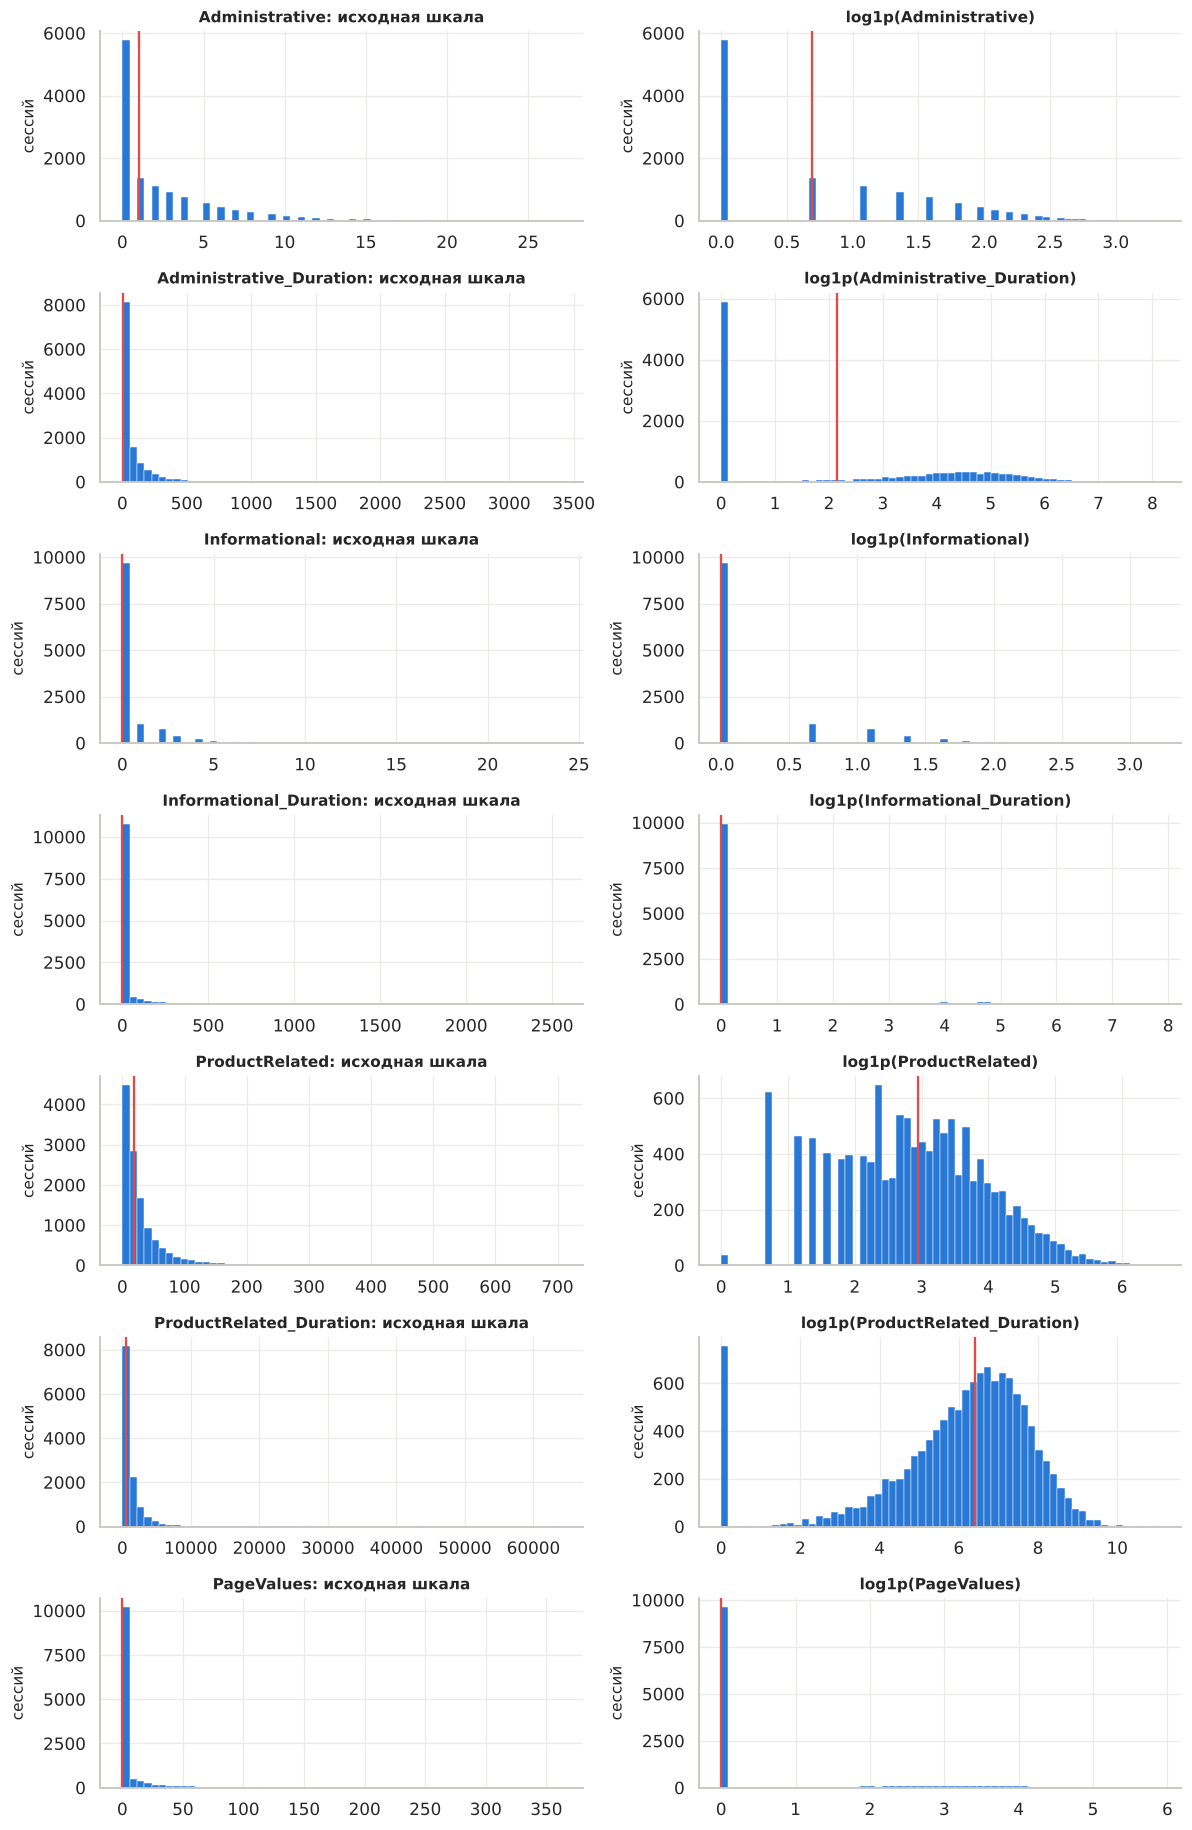

In [9]:
skewed = COUNT_DURATION + ["PageValues"]
fig, axes = plt.subplots(len(skewed), 2, figsize=(11, 2.4 * len(skewed)))
for i, c in enumerate(skewed):
    s = df[c]
    axes[i, 0].hist(s, bins=60, color=viz.BLUE, edgecolor="white", linewidth=0.3)
    axes[i, 0].axvline(s.median(), color="#e34948", lw=1.5)
    axes[i, 0].set_title(f"{c}: исходная шкала", fontsize=10)
    axes[i, 1].hist(np.log1p(s), bins=60, color=viz.BLUE, edgecolor="white", linewidth=0.3)
    axes[i, 1].axvline(np.log1p(s.median()), color="#e34948", lw=1.5)
    axes[i, 1].set_title(f"log1p({c})", fontsize=10)
    for a in axes[i]:
        a.set_ylabel("сессий")
plt.tight_layout(); plt.show()

**Что видно на гистограммах.**
* В исходной шкале почти все значения прижаты к нулю, а длинный хвост растягивает ось (у `ProductRelated_Duration` до 64 000 с), так что форму распределения не разглядеть.
* После `log1p` у каждого признака видны две части: отдельный столбец в нуле и непрерывная «гора» ненулевых значений. У `ProductRelated_Duration` эта гора близка к симметричной с центром около `log1p` ≈ 6,5 (≈ 660 с), у `Administrative_Duration` — около 4,5 (≈ 90 с).
* У `PageValues` ненулевые значения (22,1 % сессий) образуют пологое плато от `log1p` ≈ 2 до 4,5, а 77,9 % сессий сидят в нуле.

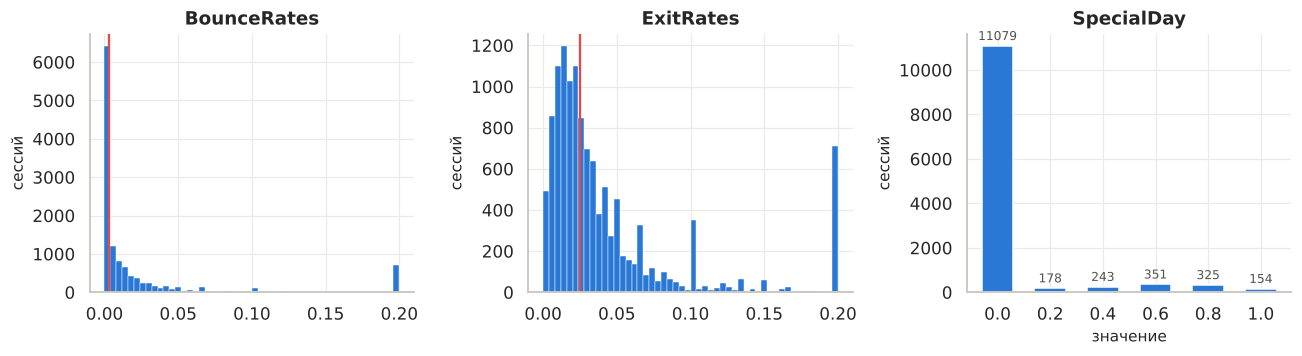

Сессий с BounceRates = 0.2 и ExitRates = 0.2: 700


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for a, c in zip(axes, ["BounceRates", "ExitRates", "SpecialDay"]):
    if c == "SpecialDay":
        vc = df[c].value_counts().sort_index()
        a.bar([f"{v:.1f}" for v in vc.index], vc.values, color=viz.BLUE, width=0.6)
        viz.annotate_bars(a)
        a.set_xlabel("значение")
    else:
        a.hist(df[c], bins=50, color=viz.BLUE, edgecolor="white", linewidth=0.3)
        a.axvline(df[c].median(), color="#e34948", lw=1.5)
    a.set_title(c); a.set_ylabel("сессий")
plt.tight_layout(); plt.show()
print("Сессий с BounceRates = 0.2 и ExitRates = 0.2:", int(((df.BounceRates == 0.2) & (df.ExitRates == 0.2)).sum()))

**`BounceRates`, `ExitRates`, `SpecialDay`.**
* У обеих метрик GA есть отдельный пик ровно на максимуме 0,2: 700 сессий имеют одновременно `BounceRates` = `ExitRates` = 0,2. Это короткие сессии с одной страницей (те же, что дают дубликаты в п. 2.2).
* `ExitRates` почти не бывает нулевым (0,6 % нулей), основная масса значений — от 0,01 до 0,05; `BounceRates` в 44,8 % сессий равен нулю.
* `SpecialDay` отличен от нуля у 1 251 сессии (10,1 %), значения распределены по пяти уровням от 0,2 до 1.

### 4.3. Диаграммы размаха (после `log1p`)

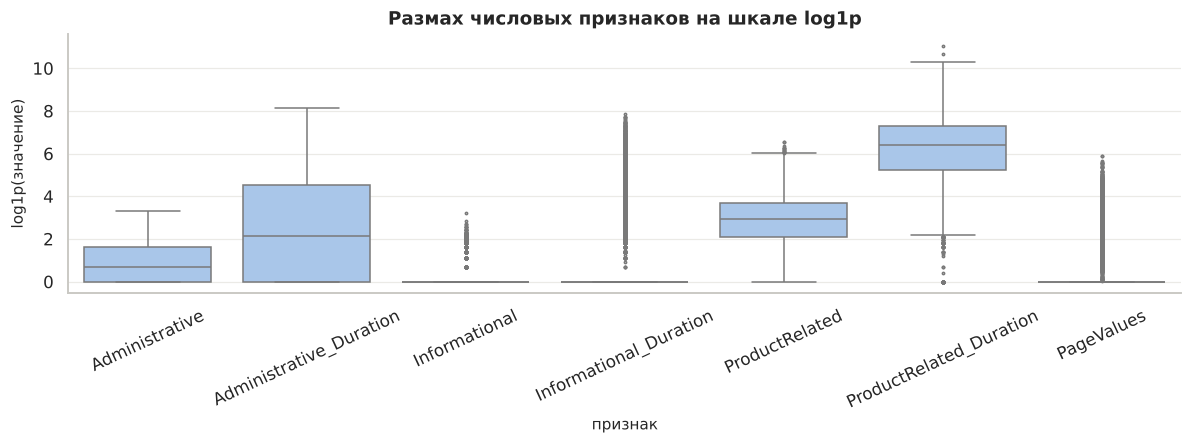

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.2))
plot_df = np.log1p(df[skewed]).melt(var_name="признак", value_name="log1p(значение)")
sns.boxplot(data=plot_df, x="признак", y="log1p(значение)", color="#9ec5f4", fliersize=1.5,
            linewidth=1, ax=ax)
ax.set_title("Размах числовых признаков на шкале log1p")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

Даже на логарифмической шкале у `Informational`, `Informational_Duration` и `PageValues` «ящик» вырожден в линию на нуле, и все ненулевые значения отрисованы как выбросы. У `ProductRelated` и `ProductRelated_Duration` ящики невырожденные, точки за усами есть с обеих сторон.

## 5. Однофакторный анализ категориальных признаков

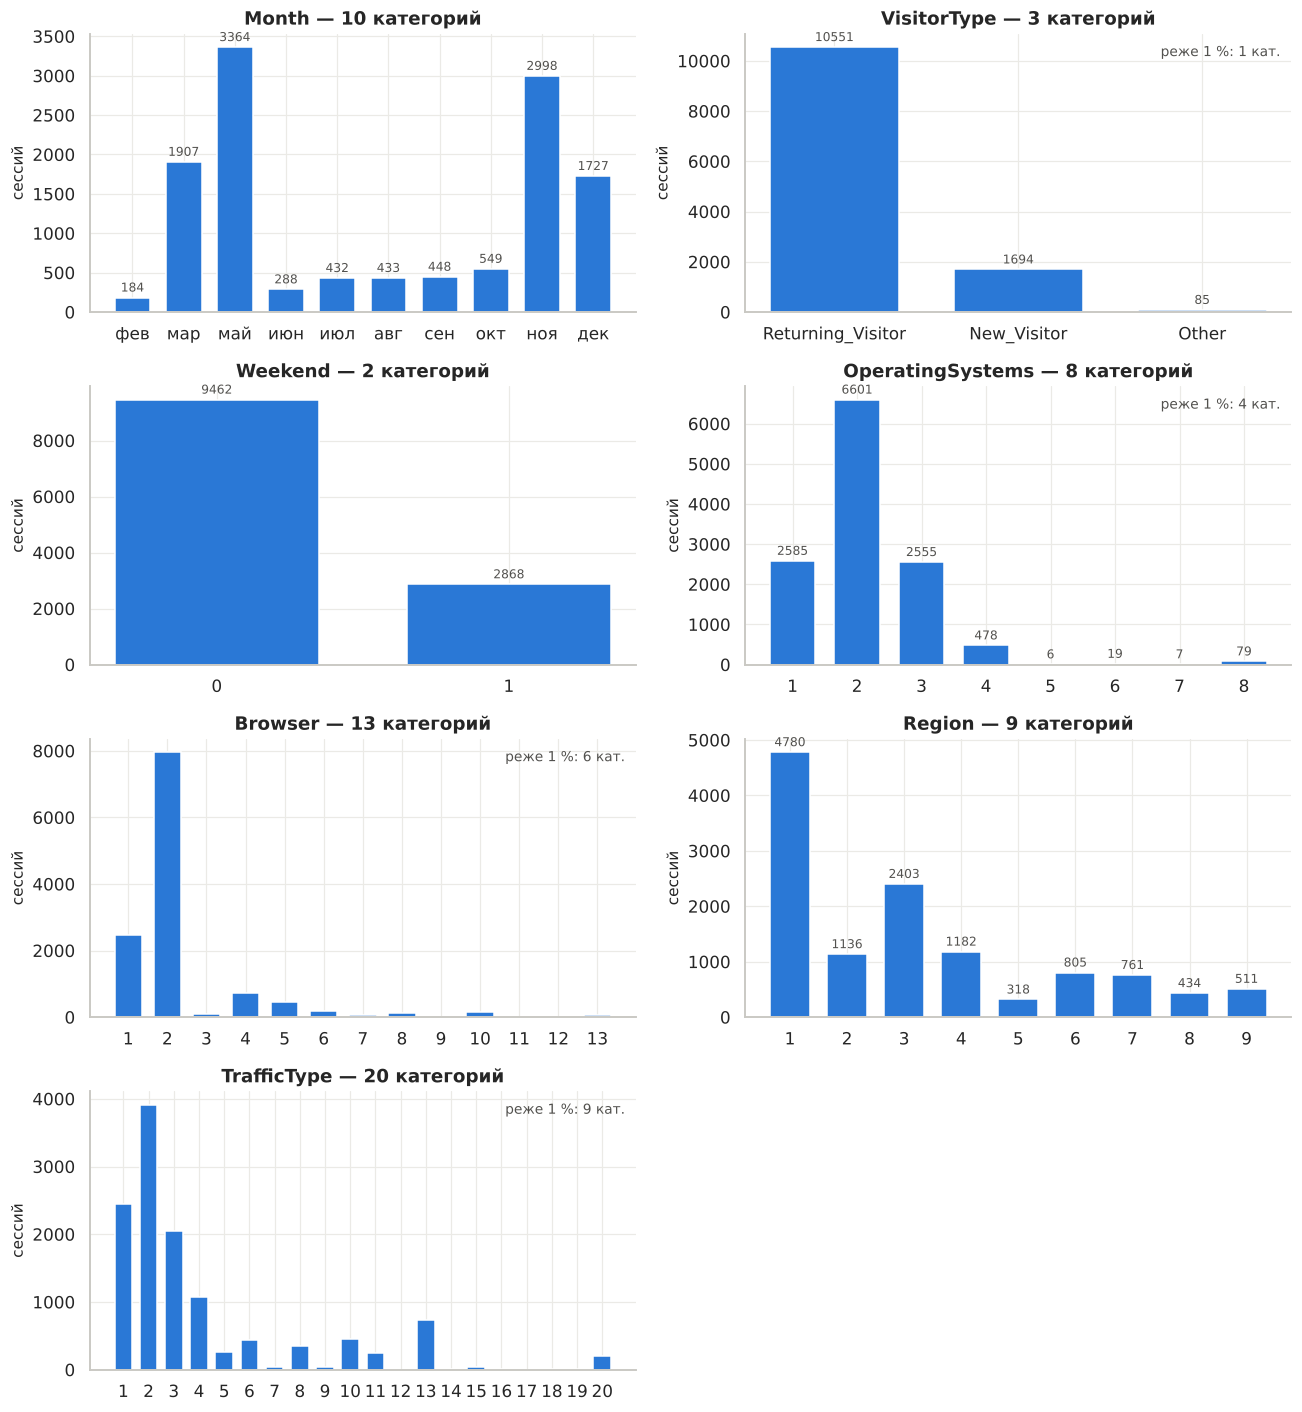

In [12]:
cat_cols = ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region", "TrafficType"]
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for a, c in zip(axes.ravel(), cat_cols):
    vc = df[c].value_counts()
    if c == "Month":
        vc = vc.reindex(MONTH_ORDER)
    else:
        vc = vc.sort_index() if c not in ["VisitorType"] else vc
    labels = [MONTH_RU[x] if c == "Month" else str(x) for x in vc.index]
    a.bar(labels, vc.values, color=viz.BLUE, width=0.7)
    a.set_title(f"{c} — {df[c].nunique()} категорий"); a.set_ylabel("сессий")
    rare = (vc / len(df) < 0.01).sum()
    if rare:
        a.text(0.98, 0.92, f"реже 1 %: {rare} кат.", transform=a.transAxes, ha="right", fontsize=9, color="#52514e")
    if len(vc) <= 10:
        viz.annotate_bars(a)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [13]:
rare_tbl = []
for c in ["OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]:
    vc = df[c].value_counts(normalize=True)
    r = vc[vc < 0.01]
    rare_tbl.append({"признак": c, "категорий": len(vc), "реже 1 %": len(r),
                     "сессий в редких": int((df[c].isin(r.index)).sum()),
                     "доля top-2": round(vc.iloc[:2].sum(), 3)})
pd.DataFrame(rare_tbl)

,признак,категорий,реже 1 %,сессий в редких,доля top-2
0,OperatingSystems,8,4,111,0.745
1,Browser,13,6,232,0.845
2,Region,9,0,0,0.583
3,TrafficType,20,9,165,0.516
4,VisitorType,3,1,85,0.993


**Наблюдения по категориальным признакам.**
* `Month`: в данных 10 месяцев — **нет января и апреля**. Больше всего сессий в мае (3 364) и ноябре (2 998), меньше всего в феврале (184).
* `VisitorType`: 85,6 % сессий — вернувшиеся посетители, 13,7 % — новые, категория `Other` — 85 сессий (0,7 %).
* `Weekend`: 2 868 сессий (23,3 %) в выходные.
* Коды `OperatingSystems`, `Browser`, `TrafficType` распределены очень неравномерно: две самые частые категории покрывают 74,5 %, 84,5 % и 51,6 % сессий соответственно, а 4, 6 и 9 категорий встречаются реже чем в 1 % сессий (у `Browser` код 9 — всего 1 сессия, у `TrafficType` коды 12 и 17 — по одной). У `Region` редких категорий нет.
* Редкие категории — кандидаты на объединение в «прочее» при one-hot кодировании, иначе получатся почти пустые столбцы (lab4).

## 6. Однофакторный анализ в разрезе целевой переменной
### 6.1. Числовые признаки по классам
Распределения сравниваю на шкале `log1p`; под графиком — таблица медиан и средних по классам и критерий Манна–Уитни (непараметрический, т. к. распределения далеки от нормального). Размер эффекта — ранговая бисериальная корреляция $r = 2U_1/(n_0 n_1) - 1$, где $U_1$ — статистика Манна–Уитни для класса «покупка»: 0 — распределения совпадают, +1 — все значения в классе «покупка» больше, −1 — все меньше.

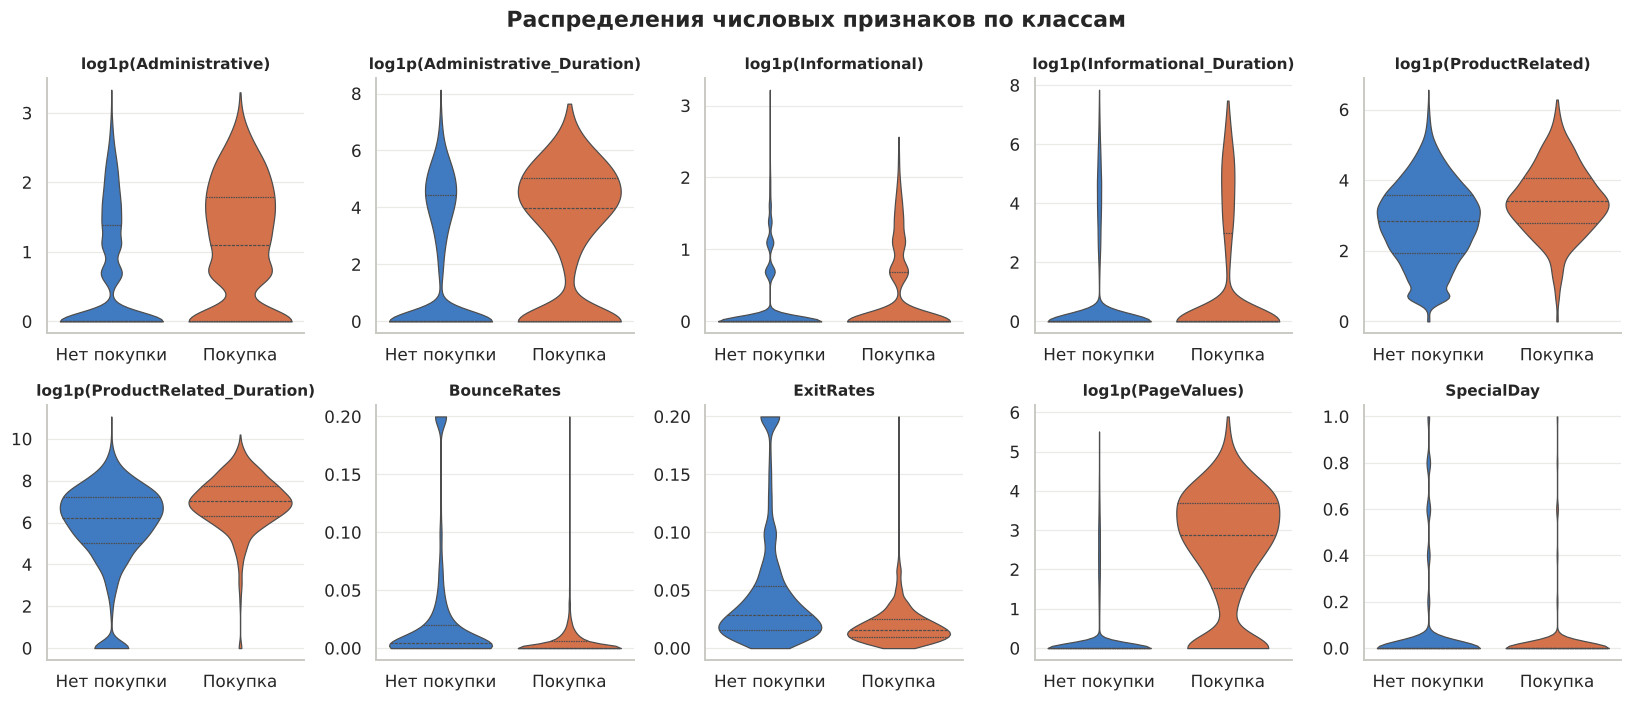

In [14]:
y_name = pd.Series(viz.class_name(df[TARGET]), index=df.index, name="класс")
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for a, c in zip(axes.ravel(), NUMERIC):
    vals = np.log1p(df[c]) if c in skewed else df[c]
    sns.violinplot(x=y_name, y=vals, hue=y_name, palette=viz.CLASS_COLORS, order=["Нет покупки", "Покупка"],
                   cut=0, inner="quartile", linewidth=0.8, ax=a, legend=False)
    a.set_title(c if c not in skewed else f"log1p({c})", fontsize=10); a.set_xlabel(""); a.set_ylabel("")
plt.suptitle("Распределения числовых признаков по классам", fontweight="bold")
plt.tight_layout(); plt.show()

In [15]:
rows = []
g0, g1 = df[df[TARGET] == 0], df[df[TARGET] == 1]
for c in NUMERIC:
    u, p = stats.mannwhitneyu(g1[c], g0[c], alternative="two-sided")
    rows.append({"признак": c, "медиана (нет покупки)": g0[c].median(), "медиана (покупка)": g1[c].median(),
                 "среднее (нет покупки)": g0[c].mean(), "среднее (покупка)": g1[c].mean(),
                 "доля нулей (нет)": (g0[c] == 0).mean(), "доля нулей (покупка)": (g1[c] == 0).mean(),
                 "p-value Манна–Уитни": p, "ранговая бисер. r": 2 * u / (len(g0) * len(g1)) - 1})
mw = pd.DataFrame(rows).set_index("признак").sort_values("ранговая бисер. r", key=abs, ascending=False)
mw.style.format({"p-value Манна–Уитни": "{:.1e}", "доля нулей (нет)": "{:.1%}", "доля нулей (покупка)": "{:.1%}"},
                precision=3).background_gradient(subset=["ранговая бисер. r"], cmap=viz.DIV, vmin=-1, vmax=1)

,медиана (нет покупки),медиана (покупка),среднее (нет покупки),среднее (покупка),доля нулей (нет),доля нулей (покупка),p-value Манна–Уитни,ранговая бисер. r
признак,,,,,,,,
PageValues,0.000,16.758,1.976,27.265,88.6%,19.4%,0.0e+00,0.727
ExitRates,0.029,0.016,0.047,0.020,0.4%,1.8%,1.2e-175,-0.406
ProductRelated_Duration,510.190,1109.906,1069.988,1876.210,7.1%,0.7%,5.3e-128,0.346
ProductRelated,16.000,29.000,28.715,48.210,0.3%,0.3%,1.1e-107,0.317
Administrative,0.000,2.000,2.118,3.394,50.4%,26.9%,1.3e-77,0.254
Administrative_Duration,0.000,52.367,73.740,119.483,51.4%,28.7%,4.7e-74,0.247
BounceRates,0.004,0.000,0.025,0.005,43.0%,54.3%,1.8e-61,-0.227
Informational,0.000,0.000,0.452,0.786,80.6%,67.9%,1.2e-36,0.130
Informational_Duration,0.000,0.000,30.236,57.611,82.3%,70.4%,1.4e-35,0.124


**Наблюдения: числовые признаки в двух классах** (описание, без объяснения причин).
* Сильнее всего различаются распределения `PageValues` (r = 0,73): в классе «покупка» нулевых значений 19,4 %, в классе «нет покупки» — 88,6 %; медианы 16,8 и 0.
* Далее по величине эффекта: `ExitRates` (r = −0,41; медиана 0,016 у покупок против 0,029), `ProductRelated_Duration` (r = 0,35; медиана 1 110 с против 510 с), `ProductRelated` (r = 0,32; медиана 29 страниц против 16).
* У `BounceRates` медиана в классе «покупка» равна 0, в другом классе — 0,004 (r = −0,23); пик на 0,2 есть только в классе «нет покупки».
* У `Informational(_Duration)` и `SpecialDay` эффект небольшой (|r| ≤ 0,13), хотя p-value очень малы: при 12 тысячах наблюдений критерий замечает даже малые различия, поэтому смотрю прежде всего на размер эффекта.

In [16]:
pv_pos = (df["PageValues"] > 0)
t = pd.crosstab(pv_pos.map({False: "PageValues = 0", True: "PageValues > 0"}), y_name)
t["всего"] = t.sum(axis=1); t["доля покупок"] = (t["Покупка"] / t["всего"]).round(3)
t

класс,Нет покупки,Покупка,всего,доля покупок
PageValues,,,,
PageValues = 0,9230,370,9600,0.039
PageValues > 0,1192,1538,2730,0.563


Отдельно про `PageValues`, раз его распределение состоит из «нуля» и «не нуля»: среди сессий с `PageValues` = 0 доля покупок 3,9 % (370 из 9 600), среди сессий с `PageValues` > 0 — 56,3 % (1 538 из 2 730).

### 6.2. Категориальные признаки по классам
Для каждой категории — доля сессий с покупкой и 95 %-ный доверительный интервал Уилсона; пунктир — средняя доля по всему датасету (15,5 %). Ширина интервала показывает, сколько в категории наблюдений: у редких категорий интервалы широкие. Для каждого признака приведён критерий χ² независимости.

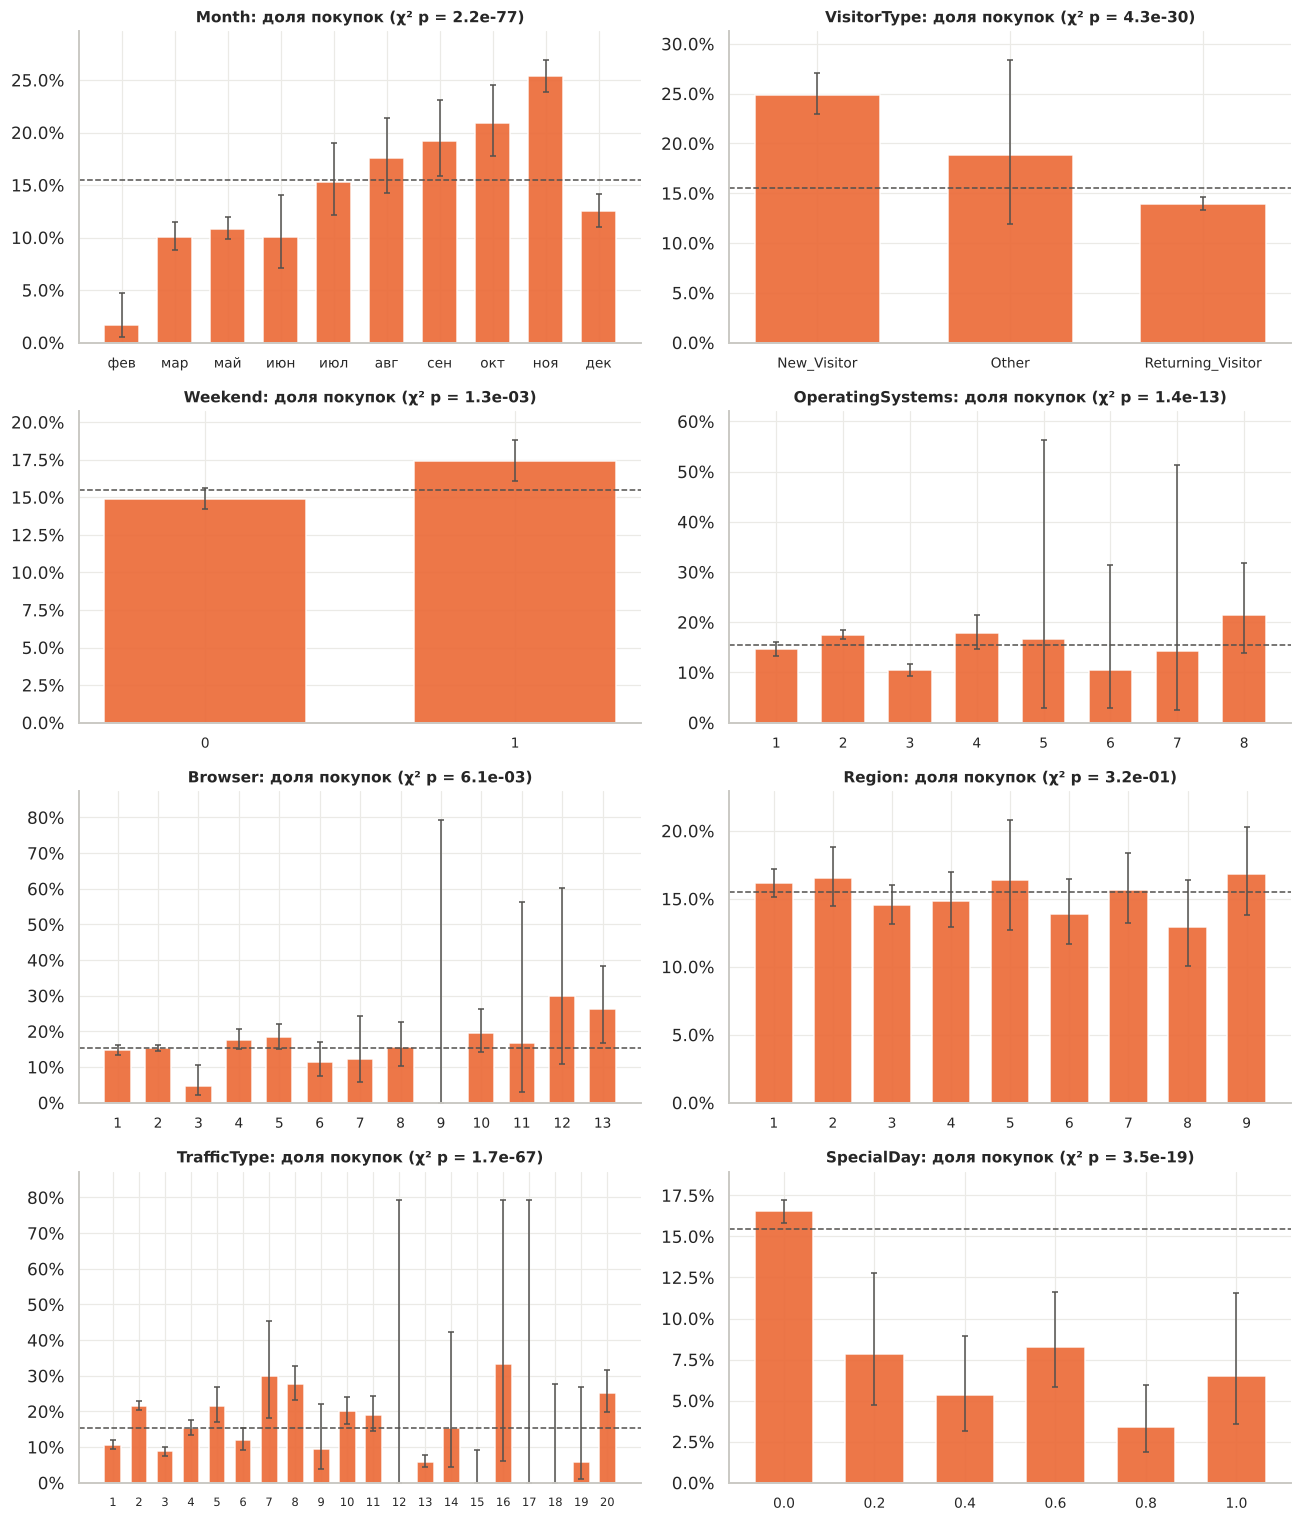

,χ²,степеней свободы,p-value
признак,,,
Month,384.9,9,2.2e-77
VisitorType,135.3,2,4.3e-30
Weekend,10.4,1,1.3e-03
OperatingSystems,75.0,7,1.4e-13
Browser,27.7,12,6.1e-03
Region,9.3,8,3.2e-01
TrafficType,373.1,19,1.7e-67
SpecialDay,96.1,5,3.5e-19


In [17]:
def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

base = df[TARGET].mean()
chi_rows = []
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for a, c in zip(axes.ravel(), cat_cols + ["SpecialDay"]):
    g = df.groupby(c, observed=True)[TARGET].agg(["sum", "count"])
    if c == "Month":
        g = g.reindex(MONTH_ORDER)
    lo, hi = wilson(g["sum"], g["count"])
    rate = g["sum"] / g["count"]
    labels = [MONTH_RU[x] if c == "Month" else str(x) for x in g.index]
    x = np.arange(len(g))
    a.bar(x, rate, color=viz.ORANGE, width=0.65, alpha=0.9)
    a.errorbar(x, rate, yerr=[rate - lo, hi - rate], fmt="none", ecolor="#52514e", elinewidth=1, capsize=2)
    a.axhline(base, ls="--", color="#52514e", lw=1)
    a.set_xticks(x, labels, fontsize=9 if len(g) < 15 else 7.5)
    a.set_ylim(0, min(1, (hi.max() if hi.max() == hi.max() else 1) * 1.1))
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[c], df[TARGET]))
    chi_rows.append({"признак": c, "χ²": chi2, "степеней свободы": dof, "p-value": p})
    a.set_title(f"{c}: доля покупок (χ² p = {p:.1e})", fontsize=10)
    a.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
pd.DataFrame(chi_rows).set_index("признак").style.format({"χ²": "{:.1f}", "p-value": "{:.1e}"})

**Наблюдения: категориальные признаки в двух классах.**
* `Month`: доля покупок меняется от 1,6 % в феврале до 25,4 % в ноябре; с июня по ноябрь значения растут от месяца к месяцу (10,1 % → 25,4 %), в декабре — 12,5 %.
* `VisitorType`: у новых посетителей доля покупок 24,9 %, у вернувшихся — 13,9 %, у `Other` — 18,8 % (интервал широкий, всего 85 сессий).
* `Weekend`: 17,4 % в выходные против 14,9 % в будни.
* `TrafficType`: разброс по кодам большой (от 0 до 33 %), но у многих кодов меньше 50 сессий и интервалы почти во всю ось — по ним доли оценены очень неточно.
* `Region`: доли по всем регионам в пределах 12,9–16,8 %, χ²-критерий не отвергает независимость (p = 0,32) — единственный такой признак.
* `SpecialDay`: при значении 0 доля покупок 16,5 %, при ненулевых значениях — от 3,4 % до 8,3 %.
* У частых кодов `OperatingSystems` (1–4) доля покупок от 10,5 % до 17,8 %, у частых браузеров (1, 2, 4, 5) — от 14,8 % до 18,4 %; у редких кодов интервалы слишком широкие для сравнения.

In [18]:
m = df.groupby("Month", observed=True).agg(сессий=(TARGET, "size"), покупок=(TARGET, "sum")).reindex(MONTH_ORDER)
m["доля покупок"] = (m["покупок"] / m["сессий"]).round(3)
m["доля от всех покупок"] = (m["покупок"] / m["покупок"].sum()).round(3)
m.index = [MONTH_RU[i] for i in m.index]
m.style.format({"доля покупок": "{:.1%}", "доля от всех покупок": "{:.1%}"})

,сессий,покупок,доля покупок,доля от всех покупок
фев,184,3,1.6%,0.2%
мар,1907,192,10.1%,10.1%
май,3364,365,10.9%,19.1%
июн,288,29,10.1%,1.5%
июл,432,66,15.3%,3.5%
авг,433,76,17.6%,4.0%
сен,448,86,19.2%,4.5%
окт,549,115,20.9%,6.0%
ноя,2998,760,25.4%,39.8%
дек,1727,216,12.5%,11.3%


На ноябрь приходится 24,3 % сессий и 39,8 % всех покупок; на май — 27,3 % сессий и 19,1 % покупок. Распределение сессий по месяцам само по себе неравномерное, поэтому одна и та же доля покупок в разных месяцах опирается на очень разное число наблюдений.

## 7. Итоги разведочного анализа (только наблюдения)

**Что я узнал о данных** (без интерпретации причин — это задача следующих этапов):

| Наблюдение | Что из этого следует для подготовки данных (lab4) |
|---|---|
| 12 330 сессий × 17 признаков, пропусков нет | импутация не нужна |
| 125 полных дубликатов — одностраничные сессии без покупки | решить, оставлять ли их (lab4) |
| нулевое время при ненулевом числе страниц — особенность GA | не считать пропуском |
| счётчики, длительности и `PageValues` сильно скошены, много нулей | для kNN / логистической регрессии / SVM — `log1p` и стандартизация; деревьям не нужно |
| пики `BounceRates` = `ExitRates` = 0,2 (700 сессий) | реальные значения, не удалять |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` — коды без порядка | one-hot, не label encoding |
| у `Browser`, `TrafficType`, `OperatingSystems`, `VisitorType` есть категории реже 1 % | объединить редкие категории в «other» |
| `Month`: 10 месяцев, нет января и апреля | one-hot; модель не сможет оценивать сессии января/апреля — ограничение данных |
| классы 84,5 % / 15,5 % | стратифицированное разбиение, метрики ROC-AUC / PR-AUC / F1 |

**Различия между классами, которые видны в данных:** сильнее всего классы различаются по `PageValues` (ненулевое значение у 80,6 % покупок и у 11,4 % «непокупок»), затем по `ExitRates`, `ProductRelated_Duration` и `ProductRelated`; среди категориальных — по `Month`, `TrafficType` и `VisitorType`; по `Region` различий не обнаружено. Насколько эти признаки полезны для прогноза и как они действуют совместно, проверяется в lab3 (корреляции и пары признаков) и lab5 (модели).